In [1]:
# AutoEdgeSim
# Comparative Simulation of Cloud, Fog, and Edge Computing
# for Autonomous Vehicle Obstacle Detection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import math

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("AutoEdgeSim Simulation Model")
print("Cloud vs Fog vs Edge")
print("Notebook initialized successfully.")

AutoEdgeSim Simulation Model
Cloud vs Fog vs Edge
Notebook initialized successfully.


In [2]:
# ==========================================
# SIMULATION CONFIGURATION
# ==========================================

NUM_SCENARIOS = 1000

# Vehicle parameters
MIN_SPEED_KMH = 30
MAX_SPEED_KMH = 100

# Obstacle parameters
MIN_OBSTACLE_DISTANCE_M = 5
MAX_OBSTACLE_DISTANCE_M = 50

OBSTACLE_SIZES = ["Small", "Medium", "Large"]

# Data packet size
MIN_PACKET_SIZE_KB = 1
MAX_PACKET_SIZE_KB = 5

print("Simulation Configuration")
print("-" * 40)
print(f"Number of scenarios      : {NUM_SCENARIOS}")
print(f"Vehicle speed range      : {MIN_SPEED_KMH}-{MAX_SPEED_KMH} km/h")
print(f"Obstacle distance range  : {MIN_OBSTACLE_DISTANCE_M}-{MAX_OBSTACLE_DISTANCE_M} m")
print(f"Packet size range        : {MIN_PACKET_SIZE_KB}-{MAX_PACKET_SIZE_KB} KB")
print(f"Obstacle sizes           : {OBSTACLE_SIZES}")

Simulation Configuration
----------------------------------------
Number of scenarios      : 1000
Vehicle speed range      : 30-100 km/h
Obstacle distance range  : 5-50 m
Packet size range        : 1-5 KB
Obstacle sizes           : ['Small', 'Medium', 'Large']


In [3]:
# ==========================================
# OBSTACLE SEVERITY AND VEHICLE DECISION
# ==========================================

def determine_severity(distance_m):
    """
    Determine obstacle severity from obstacle distance.
    """

    if distance_m > 25:
        return "SAFE"

    elif distance_m > 10:
        return "WARNING"

    else:
        return "CRITICAL"


def determine_action(severity):
    """
    Determine vehicle action based on obstacle severity.
    """

    if severity == "SAFE":
        return "CONTINUE"

    elif severity == "WARNING":
        return "SLOW DOWN"

    elif severity == "CRITICAL":
        return "EMERGENCY BRAKE"


# Test the model
test_distances = [40, 20, 8]

for distance in test_distances:
    severity = determine_severity(distance)
    action = determine_action(severity)

    print(
        f"Distance: {distance:>2} m | "
        f"Severity: {severity:<8} | "
        f"Action: {action}"
    )

Distance: 40 m | Severity: SAFE     | Action: CONTINUE
Distance: 20 m | Severity: WARNING  | Action: SLOW DOWN
Distance:  8 m | Severity: CRITICAL | Action: EMERGENCY BRAKE


In [4]:
# ==========================================
# NETWORK MODEL
# ==========================================

class NetworkModel:

    def __init__(
        self,
        bandwidth_mbps,
        propagation_delay_ms,
        base_queue_delay_ms,
        congestion_level
    ):
        self.bandwidth_mbps = bandwidth_mbps
        self.propagation_delay_ms = propagation_delay_ms
        self.base_queue_delay_ms = base_queue_delay_ms
        self.congestion_level = congestion_level

    def transmission_delay(self, packet_size_kb):
        """
        Transmission delay:
        
        T = Data Size / Bandwidth
        """

        # Convert KB to kilobits
        packet_size_kbits = packet_size_kb * 8

        # Convert Mbps to kilobits per second
        bandwidth_kbps = self.bandwidth_mbps * 1000

        # Delay in seconds
        delay_seconds = packet_size_kbits / bandwidth_kbps

        # Convert seconds to milliseconds
        delay_ms = delay_seconds * 1000

        return delay_ms

    def queue_delay(self):
        """
        Queue delay increases with network congestion.
        """

        variation = np.random.uniform(0.8, 1.2)

        delay = (
            self.base_queue_delay_ms
            * self.congestion_level
            * variation
        )

        return delay

    def total_network_delay(self, packet_size_kb):
        """
        Total network delay.
        """

        transmission = self.transmission_delay(packet_size_kb)

        propagation = self.propagation_delay_ms

        queue = self.queue_delay()

        total = transmission + propagation + queue

        return {
            "transmission_delay_ms": transmission,
            "propagation_delay_ms": propagation,
            "queue_delay_ms": queue,
            "total_network_delay_ms": total
        }

In [5]:
# ==========================================
# TEST NETWORK MODEL
# ==========================================

test_network = NetworkModel(
    bandwidth_mbps=100,
    propagation_delay_ms=20,
    base_queue_delay_ms=5,
    congestion_level=1.0
)

packet_size = 2

network_result = test_network.total_network_delay(packet_size)

print("Network Simulation")
print("-" * 40)
print(f"Packet size          : {packet_size} KB")
print(f"Bandwidth            : {test_network.bandwidth_mbps} Mbps")
print(f"Transmission delay   : {network_result['transmission_delay_ms']:.3f} ms")
print(f"Propagation delay    : {network_result['propagation_delay_ms']:.3f} ms")
print(f"Queue delay          : {network_result['queue_delay_ms']:.3f} ms")
print(f"Total network delay  : {network_result['total_network_delay_ms']:.3f} ms")

Network Simulation
----------------------------------------
Packet size          : 2 KB
Bandwidth            : 100 Mbps
Transmission delay   : 0.160 ms
Propagation delay    : 20.000 ms
Queue delay          : 4.749 ms
Total network delay  : 24.909 ms


In [6]:
# ==========================================
# CLOUD, FOG AND EDGE PARAMETERS
# ==========================================

ARCHITECTURES = {
    "Cloud": {
        "bandwidth_mbps": 100,
        "propagation_delay_ms": 20,
        "base_queue_delay_ms": 8,
        "congestion_level": 1.5,
        "processing_capacity": 1.0
    },

    "Fog": {
        "bandwidth_mbps": 200,
        "propagation_delay_ms": 8,
        "base_queue_delay_ms": 4,
        "congestion_level": 1.2,
        "processing_capacity": 2.0
    },

    "Edge": {
        "bandwidth_mbps": 500,
        "propagation_delay_ms": 2,
        "base_queue_delay_ms": 1.5,
        "congestion_level": 1.0,
        "processing_capacity": 4.0
    }
}

# Display the parameters
parameters_df = pd.DataFrame(ARCHITECTURES).T

parameters_df

,bandwidth_mbps,propagation_delay_ms,base_queue_delay_ms,congestion_level,processing_capacity
Cloud,100.0,20.0,8.0,1.5,1.0
Fog,200.0,8.0,4.0,1.2,2.0
Edge,500.0,2.0,1.5,1.0,4.0


In [7]:
# ==========================================
# PROCESSING MODEL
# ==========================================

class ProcessingModel:

    def __init__(self, processing_capacity):
        self.processing_capacity = processing_capacity

    def processing_delay(self, vehicle_speed, obstacle_distance, obstacle_size):
        """
        Simulates computation time required to process
        the vehicle and obstacle information.
        """

        # Base computational workload
        workload = 10

        # Higher vehicle speed slightly increases workload
        speed_factor = vehicle_speed / 100

        # Closer obstacles require faster decision processing
        distance_factor = max(0.5, (50 - obstacle_distance) / 50)

        # Larger obstacles require slightly more processing
        size_factor = {
            "Small": 1.0,
            "Medium": 1.2,
            "Large": 1.5
        }[obstacle_size]

        total_workload = (
            workload
            * speed_factor
            * distance_factor
            * size_factor
        )

        # Higher processing capacity reduces processing time
        delay_ms = (
            total_workload
            / self.processing_capacity
        )

        # Add small variation to represent changing workload
        variation = np.random.uniform(0.9, 1.1)

        return delay_ms * variation

In [8]:
# ==========================================
# TEST PROCESSING MODEL
# ==========================================

test_processing = ProcessingModel(
    processing_capacity=2.0
)

processing_time = test_processing.processing_delay(
    vehicle_speed=72,
    obstacle_distance=14,
    obstacle_size="Large"
)

print("Processing Simulation")
print("-" * 40)
print(f"Vehicle speed       : 72 km/h")
print(f"Obstacle distance   : 14 m")
print(f"Obstacle size       : Large")
print(f"Processing time     : {processing_time:.3f} ms")

Processing Simulation
----------------------------------------
Vehicle speed       : 72 km/h
Obstacle distance   : 14 m
Obstacle size       : Large
Processing time     : 4.238 ms


In [9]:
# ==========================================
# SINGLE SCENARIO SIMULATION
# ==========================================

def simulate_architecture(
    architecture_name,
    vehicle_speed,
    obstacle_distance,
    obstacle_size,
    packet_size_kb
):
    """
    Simulate one scenario on a specific architecture.
    """

    params = ARCHITECTURES[architecture_name]

    # Create network model
    network = NetworkModel(
        bandwidth_mbps=params["bandwidth_mbps"],
        propagation_delay_ms=params["propagation_delay_ms"],
        base_queue_delay_ms=params["base_queue_delay_ms"],
        congestion_level=params["congestion_level"]
    )

    # Create processing model
    processing = ProcessingModel(
        processing_capacity=params["processing_capacity"]
    )

    # Calculate network delay
    network_result = network.total_network_delay(
        packet_size_kb
    )

    # Calculate processing delay
    processing_delay = processing.processing_delay(
        vehicle_speed,
        obstacle_distance,
        obstacle_size
    )

    # Calculate total latency
    total_latency = (
        network_result["total_network_delay_ms"]
        + processing_delay
    )

    # Determine obstacle severity
    severity = determine_severity(
        obstacle_distance
    )

    # Determine vehicle action
    action = determine_action(
        severity
    )

    return {
        "architecture": architecture_name,
        "vehicle_speed_kmh": vehicle_speed,
        "obstacle_distance_m": obstacle_distance,
        "obstacle_size": obstacle_size,
        "packet_size_kb": packet_size_kb,
        "severity": severity,
        "action": action,
        "transmission_delay_ms":
            network_result["transmission_delay_ms"],
        "propagation_delay_ms":
            network_result["propagation_delay_ms"],
        "queue_delay_ms":
            network_result["queue_delay_ms"],
        "network_delay_ms":
            network_result["total_network_delay_ms"],
        "processing_delay_ms":
            processing_delay,
        "total_latency_ms":
            total_latency
    }

In [10]:
# ==========================================
# TEST ONE COMPLETE SCENARIO
# ==========================================

vehicle_speed = 72
obstacle_distance = 14
obstacle_size = "Large"
packet_size = 2

results = []

for architecture in ["Cloud", "Fog", "Edge"]:

    result = simulate_architecture(
        architecture_name=architecture,
        vehicle_speed=vehicle_speed,
        obstacle_distance=obstacle_distance,
        obstacle_size=obstacle_size,
        packet_size_kb=packet_size
    )

    results.append(result)

single_scenario_df = pd.DataFrame(results)

single_scenario_df[
    [
        "architecture",
        "severity",
        "action",
        "network_delay_ms",
        "processing_delay_ms",
        "total_latency_ms"
    ]
]

,architecture,severity,action,network_delay_ms,processing_delay_ms,total_latency_ms
0,Cloud,WARNING,SLOW DOWN,33.273571,7.929434,41.203005
1,Fog,WARNING,SLOW DOWN,12.219556,3.620501,15.840057
2,Edge,WARNING,SLOW DOWN,3.266850,2.086369,5.353219


In [11]:
# ==========================================
# SCENARIO GENERATOR
# ==========================================

def generate_scenario(scenario_id):
    """
    Generate one virtual autonomous vehicle scenario.
    """

    vehicle_speed = random.randint(
        MIN_SPEED_KMH,
        MAX_SPEED_KMH
    )

    obstacle_distance = round(
        random.uniform(
            MIN_OBSTACLE_DISTANCE_M,
            MAX_OBSTACLE_DISTANCE_M
        ),
        2
    )

    obstacle_size = random.choice(
        OBSTACLE_SIZES
    )

    packet_size = round(
        random.uniform(
            MIN_PACKET_SIZE_KB,
            MAX_PACKET_SIZE_KB
        ),
        2
    )

    severity = determine_severity(
        obstacle_distance
    )

    action = determine_action(
        severity
    )

    return {
        "scenario_id": scenario_id,
        "vehicle_speed_kmh": vehicle_speed,
        "obstacle_distance_m": obstacle_distance,
        "obstacle_size": obstacle_size,
        "packet_size_kb": packet_size,
        "severity": severity,
        "action": action
    }


# Generate test scenarios
test_scenarios = [
    generate_scenario(i)
    for i in range(1, 11)
]

test_scenarios_df = pd.DataFrame(
    test_scenarios
)

test_scenarios_df

,scenario_id,vehicle_speed_kmh,obstacle_distance_m,obstacle_size,packet_size_kb,severity,action
0,1,44,6.13,Medium,1.98,CRITICAL,EMERGENCY BRAKE
1,2,47,38.14,Large,3.96,SAFE,CONTINUE
2,3,99,8.91,Medium,1.13,CRITICAL,EMERGENCY BRAKE
3,4,41,14.84,Large,3.41,WARNING,SLOW DOWN
4,5,55,37.22,Large,3.18,SAFE,CONTINUE
5,6,58,25.21,Medium,4.24,SAFE,CONTINUE
6,7,30,39.15,Small,3.79,SAFE,CONTINUE
7,8,73,17.50,Small,4.83,WARNING,SLOW DOWN
8,9,73,9.60,Medium,1.39,CRITICAL,EMERGENCY BRAKE
9,10,74,32.17,Small,3.92,SAFE,CONTINUE


In [14]:
# ==========================================
# COMPLETE SIMULATION ENGINE
# ==========================================

def run_simulation(num_scenarios=1000):

    all_results = []

    for scenario_id in range(1, num_scenarios + 1):

        # Generate ONE scenario
        scenario = generate_scenario(
            scenario_id
        )

        # Send SAME scenario to all architectures
        for architecture in [
            "Cloud",
            "Fog",
            "Edge"
        ]:

            result = simulate_architecture(
                architecture_name=architecture,
                vehicle_speed=scenario[
                    "vehicle_speed_kmh"
                ],
                obstacle_distance=scenario[
                    "obstacle_distance_m"
                ],
                obstacle_size=scenario[
                    "obstacle_size"
                ],
                packet_size_kb=scenario[
                    "packet_size_kb"
                ]
            )

            # Add scenario ID
            result["scenario_id"] = scenario_id

            all_results.append(result)

    return pd.DataFrame(all_results)

In [16]:
print("Checking whether results_df exists...")

try:
    print(results_df.shape)
    print("results_df exists successfully.")
except NameError:
    print("ERROR: results_df does not exist.")

Checking whether results_df exists...
ERROR: results_df does not exist.


In [18]:
# ==========================================
# RUN SIMULATION
# ==========================================

results_df = run_simulation(
    num_scenarios=1000
)

print("Simulation completed.")
print(f"Total result records: {len(results_df)}")

display(results_df.head())

Simulation completed.
Total result records: 3000


,architecture,vehicle_speed_kmh,obstacle_distance_m,obstacle_size,packet_size_kb,severity,action,transmission_delay_ms,propagation_delay_ms,queue_delay_ms,network_delay_ms,processing_delay_ms,total_latency_ms,scenario_id
0,Cloud,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.10560,20,12.485352,32.590952,9.647617,42.238569,1
1,Fog,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.05280,8,3.879522,11.932322,5.066327,16.998649,1
2,Edge,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.02112,2,1.699466,3.720586,2.182326,5.902911,1
3,Cloud,67,42.32,Large,4.54,SAFE,CONTINUE,0.36320,20,10.472760,30.835960,4.706822,35.542781,2
4,Fog,67,42.32,Large,4.54,SAFE,CONTINUE,0.18160,8,4.424145,12.605745,2.524940,15.130685,2


In [19]:
# ==========================================
# BASIC RESULT CHECK
# ==========================================

print("Rows:", len(results_df))
print("Columns:", len(results_df.columns))

print("\nArchitectures:")
print(results_df["architecture"].value_counts())

print("\nSeverity distribution:")
print(results_df["severity"].value_counts())

print("\nFirst 10 results:")
display(results_df.head(10))

Rows: 3000
Columns: 14

Architectures:
architecture
Cloud    1000
Fog      1000
Edge     1000
Name: count, dtype: int64

Severity distribution:
severity
SAFE        1626
WARNING     1071
CRITICAL     303
Name: count, dtype: int64

First 10 results:


,architecture,vehicle_speed_kmh,obstacle_distance_m,obstacle_size,packet_size_kb,severity,action,transmission_delay_ms,propagation_delay_ms,queue_delay_ms,network_delay_ms,processing_delay_ms,total_latency_ms,scenario_id
0,Cloud,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.10560,20,12.485352,32.590952,9.647617,42.238569,1
1,Fog,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.05280,8,3.879522,11.932322,5.066327,16.998649,1
2,Edge,98,10.62,Medium,1.32,WARNING,SLOW DOWN,0.02112,2,1.699466,3.720586,2.182326,5.902911,1
3,Cloud,67,42.32,Large,4.54,SAFE,CONTINUE,0.36320,20,10.472760,30.835960,4.706822,35.542781,2
4,Fog,67,42.32,Large,4.54,SAFE,CONTINUE,0.18160,8,4.424145,12.605745,2.524940,15.130685,2
5,Edge,67,42.32,Large,4.54,SAFE,CONTINUE,0.07264,2,1.459167,3.531807,1.203796,4.735603,2
6,Cloud,76,30.98,Large,1.28,SAFE,CONTINUE,0.10240,20,12.536894,32.639294,5.289023,37.928317,3
7,Fog,76,30.98,Large,1.28,SAFE,CONTINUE,0.05120,8,4.400918,12.452118,2.773826,15.225944,3
8,Edge,76,30.98,Large,1.28,SAFE,CONTINUE,0.02048,2,1.473642,3.494122,1.506275,5.000397,3
9,Cloud,59,39.79,Small,4.42,SAFE,CONTINUE,0.35360,20,10.558434,30.912034,2.958398,33.870432,4


In [20]:
# ==========================================
# PERFORMANCE ANALYSIS
# ==========================================

performance_summary = (
    results_df
    .groupby("architecture")
    .agg(
        average_latency_ms=("total_latency_ms", "mean"),
        minimum_latency_ms=("total_latency_ms", "min"),
        maximum_latency_ms=("total_latency_ms", "max"),
        std_latency_ms=("total_latency_ms", "std"),
        average_network_delay_ms=("network_delay_ms", "mean"),
        average_processing_delay_ms=("processing_delay_ms", "mean"),
        average_transmission_delay_ms=("transmission_delay_ms", "mean"),
        average_queue_delay_ms=("queue_delay_ms", "mean")
    )
    .round(3)
)

display(performance_summary)

,average_latency_ms,minimum_latency_ms,maximum_latency_ms,std_latency_ms,average_network_delay_ms,average_processing_delay_ms,average_transmission_delay_ms,average_queue_delay_ms
architecture,,,,,,,,
Cloud,36.934,31.699,45.255,2.502,32.147,4.787,0.239,11.908
Edge,4.738,3.699,7.007,0.543,3.550,1.189,0.048,1.502
Fog,15.298,12.971,19.664,1.139,12.919,2.379,0.120,4.799


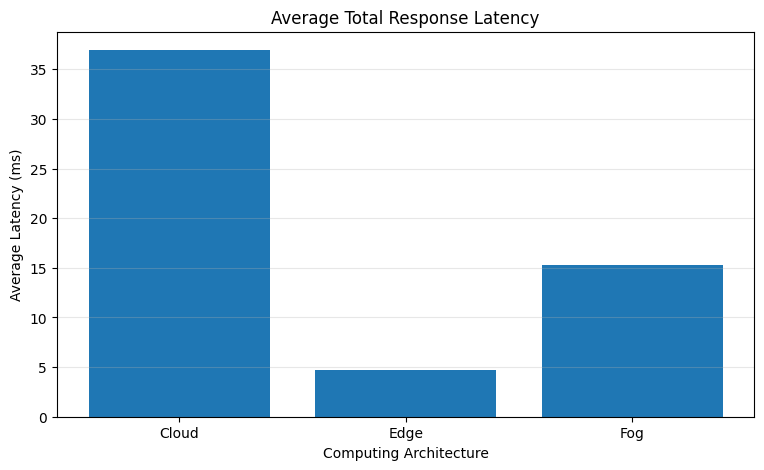

In [21]:
# ==========================================
# AVERAGE LATENCY COMPARISON
# ==========================================

plt.figure(figsize=(9, 5))

architectures = performance_summary.index
latencies = performance_summary["average_latency_ms"]

plt.bar(architectures, latencies)

plt.title("Average Total Response Latency")
plt.xlabel("Computing Architecture")
plt.ylabel("Average Latency (ms)")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [22]:
# ==========================================
# CONGESTION EXPERIMENT
# ==========================================

CONGESTION_LEVELS = {
    "Low": 0.5,
    "Medium": 1.0,
    "High": 2.0
}

congestion_results = []

for congestion_name, congestion_value in CONGESTION_LEVELS.items():

    for architecture_name in ARCHITECTURES:

        # Copy architecture parameters
        params = ARCHITECTURES[architecture_name].copy()

        # Change only congestion
        params["congestion_level"] = congestion_value

        total_latencies = []

        for _ in range(1000):

            scenario = generate_scenario(_ + 1)

            network = NetworkModel(
                bandwidth_mbps=params["bandwidth_mbps"],
                propagation_delay_ms=params["propagation_delay_ms"],
                base_queue_delay_ms=params["base_queue_delay_ms"],
                congestion_level=params["congestion_level"]
            )

            processing = ProcessingModel(
                processing_capacity=params["processing_capacity"]
            )

            network_result = network.total_network_delay(
                scenario["packet_size_kb"]
            )

            processing_delay = processing.processing_delay(
                scenario["vehicle_speed_kmh"],
                scenario["obstacle_distance_m"],
                scenario["obstacle_size"]
            )

            total_latency = (
                network_result["total_network_delay_ms"]
                + processing_delay
            )

            total_latencies.append(total_latency)

        congestion_results.append({
            "congestion": congestion_name,
            "architecture": architecture_name,
            "average_latency_ms": np.mean(total_latencies)
        })

congestion_df = pd.DataFrame(congestion_results)

display(congestion_df)

,congestion,architecture,average_latency_ms
0,Low,Cloud,28.919396
1,Low,Fog,12.468042
2,Low,Edge,3.997662
3,Medium,Cloud,33.016260
4,Medium,Fog,14.453424
5,Medium,Edge,4.749023
6,High,Cloud,40.930633
7,High,Fog,18.568853
8,High,Edge,6.246712


In [23]:
# ==========================================
# PROCESSING LOAD EXPERIMENT
# ==========================================

PROCESSING_LOADS = {
    "Low": 0.5,
    "Medium": 1.0,
    "High": 2.0,
    "Very High": 3.0
}

processing_results = []

for load_name, load_multiplier in PROCESSING_LOADS.items():

    for architecture_name in ARCHITECTURES:

        params = ARCHITECTURES[architecture_name]

        total_latencies = []

        for scenario_id in range(1, 1001):

            scenario = generate_scenario(scenario_id)

            # Network model
            network = NetworkModel(
                bandwidth_mbps=params["bandwidth_mbps"],
                propagation_delay_ms=params["propagation_delay_ms"],
                base_queue_delay_ms=params["base_queue_delay_ms"],
                congestion_level=params["congestion_level"]
            )

            # Increase computational workload
            processing = ProcessingModel(
                processing_capacity=(
                    params["processing_capacity"]
                    / load_multiplier
                )
            )

            network_result = network.total_network_delay(
                scenario["packet_size_kb"]
            )

            processing_delay = processing.processing_delay(
                scenario["vehicle_speed_kmh"],
                scenario["obstacle_distance_m"],
                scenario["obstacle_size"]
            )

            total_latency = (
                network_result["total_network_delay_ms"]
                + processing_delay
            )

            total_latencies.append(total_latency)

        processing_results.append({
            "processing_load": load_name,
            "architecture": architecture_name,
            "average_latency_ms": np.mean(total_latencies)
        })

processing_df = pd.DataFrame(processing_results)

display(processing_df)

,processing_load,architecture,average_latency_ms
0,Low,Cloud,34.594470
1,Low,Fog,14.108474
2,Low,Edge,4.123545
3,Medium,Cloud,37.024166
4,Medium,Fog,15.288429
5,Medium,Edge,4.752808
6,High,Cloud,41.762898
7,High,Fog,17.515364
8,High,Edge,5.951724
9,Very High,Cloud,46.578699


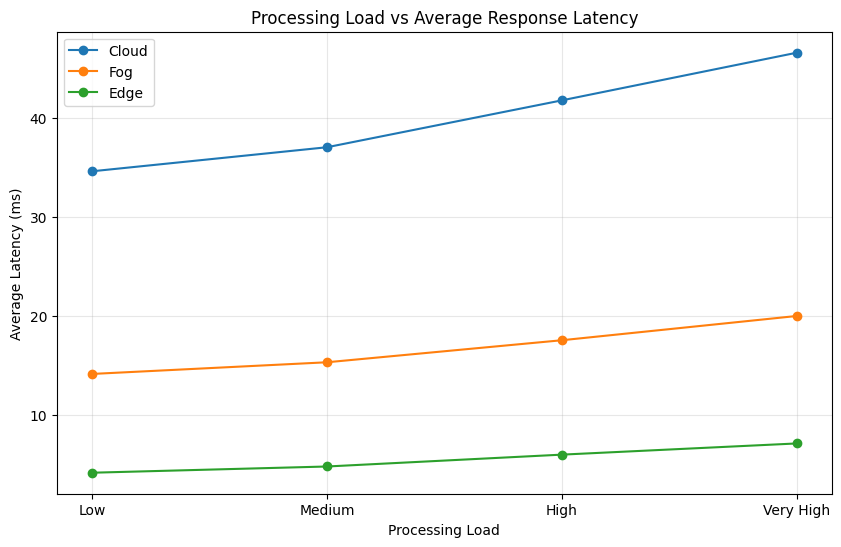

In [24]:
# ==========================================
# PROCESSING LOAD VS LATENCY
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = processing_df[
        processing_df["architecture"] == architecture
    ]

    plt.plot(
        data["processing_load"],
        data["average_latency_ms"],
        marker="o",
        label=architecture
    )

plt.title("Processing Load vs Average Response Latency")
plt.xlabel("Processing Load")
plt.ylabel("Average Latency (ms)")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [25]:
# ==========================================
# BANDWIDTH EXPERIMENT
# ==========================================

PACKET_SIZES = [1, 2, 3, 4, 5]

bandwidth_results = []

for architecture_name in ARCHITECTURES:

    params = ARCHITECTURES[architecture_name]

    network = NetworkModel(
        bandwidth_mbps=params["bandwidth_mbps"],
        propagation_delay_ms=params["propagation_delay_ms"],
        base_queue_delay_ms=params["base_queue_delay_ms"],
        congestion_level=params["congestion_level"]
    )

    for packet_size in PACKET_SIZES:

        transmission_delays = []

        for _ in range(1000):

            delay = network.transmission_delay(
                packet_size
            )

            transmission_delays.append(delay)

        bandwidth_results.append({
            "architecture": architecture_name,
            "packet_size_kb": packet_size,
            "average_transmission_delay_ms":
                np.mean(transmission_delays)
        })

bandwidth_df = pd.DataFrame(
    bandwidth_results
)

display(bandwidth_df)

,architecture,packet_size_kb,average_transmission_delay_ms
0,Cloud,1,0.080
1,Cloud,2,0.160
2,Cloud,3,0.240
3,Cloud,4,0.320
4,Cloud,5,0.400
5,Fog,1,0.040
6,Fog,2,0.080
7,Fog,3,0.120
8,Fog,4,0.160
9,Fog,5,0.200


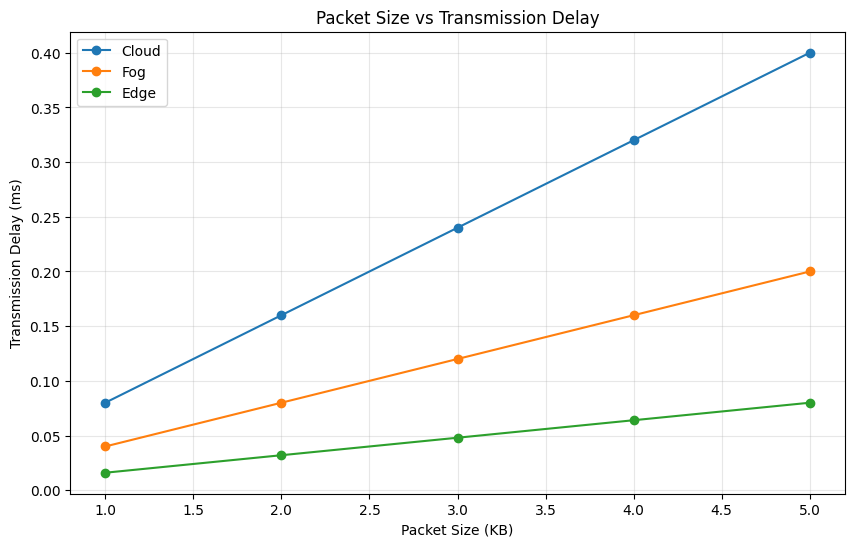

In [26]:
# ==========================================
# PACKET SIZE VS TRANSMISSION DELAY
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = bandwidth_df[
        bandwidth_df["architecture"] == architecture
    ]

    plt.plot(
        data["packet_size_kb"],
        data["average_transmission_delay_ms"],
        marker="o",
        label=architecture
    )

plt.title("Packet Size vs Transmission Delay")
plt.xlabel("Packet Size (KB)")
plt.ylabel("Transmission Delay (ms)")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


In [27]:
# ==========================================
# MODEL VALIDATION - TRANSMISSION DELAY
# ==========================================

validation_rows = []

for architecture, params in ARCHITECTURES.items():

    bandwidth = params["bandwidth_mbps"]

    for packet_size in [1, 2, 5]:

        # Theoretical calculation
        theoretical_delay = (
            (packet_size * 8)
            / (bandwidth * 1000)
        ) * 1000

        # Model calculation
        network = NetworkModel(
            bandwidth_mbps=bandwidth,
            propagation_delay_ms=params["propagation_delay_ms"],
            base_queue_delay_ms=params["base_queue_delay_ms"],
            congestion_level=params["congestion_level"]
        )

        model_delay = network.transmission_delay(
            packet_size
        )

        error = abs(
            theoretical_delay - model_delay
        )

        validation_rows.append({
            "architecture": architecture,
            "packet_size_kb": packet_size,
            "theoretical_delay_ms": theoretical_delay,
            "model_delay_ms": model_delay,
            "absolute_error_ms": error
        })

validation_df = pd.DataFrame(validation_rows)

display(validation_df)

,architecture,packet_size_kb,theoretical_delay_ms,model_delay_ms,absolute_error_ms
0,Cloud,1,0.080,0.080,0.0
1,Cloud,2,0.160,0.160,0.0
2,Cloud,5,0.400,0.400,0.0
3,Fog,1,0.040,0.040,0.0
4,Fog,2,0.080,0.080,0.0
5,Fog,5,0.200,0.200,0.0
6,Edge,1,0.016,0.016,0.0
7,Edge,2,0.032,0.032,0.0
8,Edge,5,0.080,0.080,0.0


In [28]:
# ==========================================
# COMPLETE LATENCY MODEL VALIDATION
# ==========================================

results_df["calculated_total_latency_ms"] = (
    results_df["network_delay_ms"]
    + results_df["processing_delay_ms"]
)

results_df["latency_error_ms"] = (
    results_df["total_latency_ms"]
    - results_df["calculated_total_latency_ms"]
)

validation_summary = (
    results_df["latency_error_ms"]
    .abs()
    .agg(
        ["min", "max", "mean"]
    )
)

print("Latency Model Validation")
print("-" * 40)

print(f"Minimum error : {validation_summary['min']:.10f} ms")
print(f"Maximum error : {validation_summary['max']:.10f} ms")
print(f"Mean error    : {validation_summary['mean']:.10f} ms")

Latency Model Validation
----------------------------------------
Minimum error : 0.0000000000 ms
Maximum error : 0.0000000000 ms
Mean error    : 0.0000000000 ms


In [29]:
# ==========================================
# MODEL COMPONENT VALIDATION
# ==========================================

components = [
    "transmission_delay_ms",
    "propagation_delay_ms",
    "queue_delay_ms",
    "processing_delay_ms",
    "network_delay_ms",
    "total_latency_ms"
]

validation_check = pd.DataFrame({
    "Component": components,
    "Minimum": [
        results_df[c].min()
        for c in components
    ],
    "Maximum": [
        results_df[c].max()
        for c in components
    ],
    "Average": [
        results_df[c].mean()
        for c in components
    ]
}).round(4)

display(validation_check)

,Component,Minimum,Maximum,Average
0,transmission_delay_ms,0.0160,0.4000,0.1355
1,propagation_delay_ms,2.0000,20.0000,10.0000
2,queue_delay_ms,1.2001,14.3892,6.0696
3,processing_delay_ms,0.3659,12.7202,2.7849
4,network_delay_ms,3.2272,34.7182,16.2051
5,total_latency_ms,3.6990,45.2549,18.9900


In [30]:
# ==========================================
# FINAL BASELINE PERFORMANCE SUMMARY
# ==========================================

final_summary = (
    results_df
    .groupby("architecture")
    .agg(
        scenarios=("scenario_id", "count"),
        avg_total_latency_ms=("total_latency_ms", "mean"),
        min_latency_ms=("total_latency_ms", "min"),
        max_latency_ms=("total_latency_ms", "max"),
        std_latency_ms=("total_latency_ms", "std"),
        avg_network_delay_ms=("network_delay_ms", "mean"),
        avg_processing_delay_ms=("processing_delay_ms", "mean"),
        avg_transmission_delay_ms=("transmission_delay_ms", "mean"),
        avg_queue_delay_ms=("queue_delay_ms", "mean")
    )
    .round(3)
)

display(final_summary)

,scenarios,avg_total_latency_ms,min_latency_ms,max_latency_ms,std_latency_ms,avg_network_delay_ms,avg_processing_delay_ms,avg_transmission_delay_ms,avg_queue_delay_ms
architecture,,,,,,,,,
Cloud,1000,36.934,31.699,45.255,2.502,32.147,4.787,0.239,11.908
Edge,1000,4.738,3.699,7.007,0.543,3.550,1.189,0.048,1.502
Fog,1000,15.298,12.971,19.664,1.139,12.919,2.379,0.120,4.799


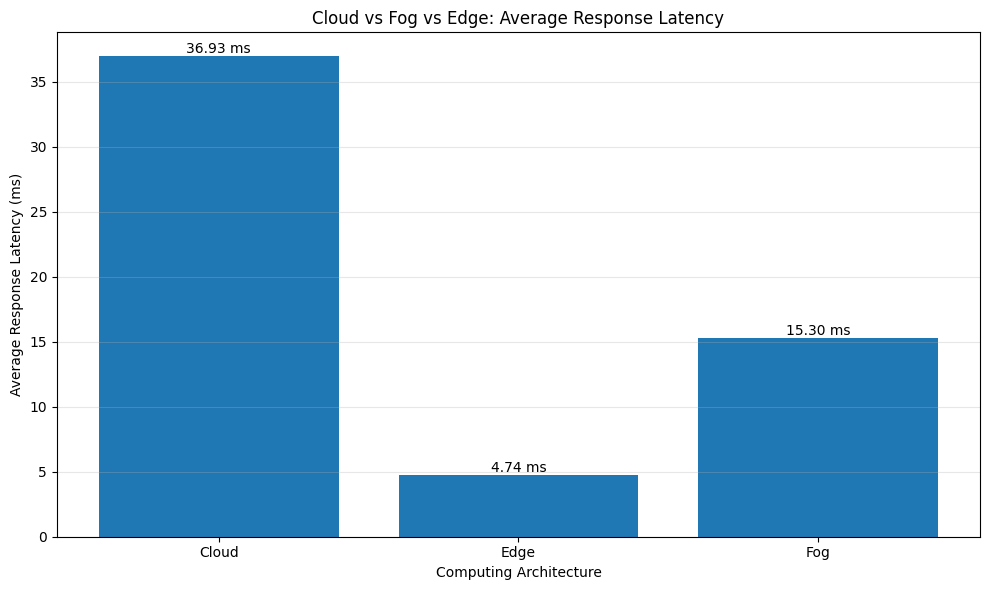

In [31]:
# ==========================================
# FINAL BASELINE LATENCY COMPARISON
# ==========================================

plt.figure(figsize=(10, 6))

architectures = final_summary.index
latencies = final_summary["avg_total_latency_ms"]

bars = plt.bar(
    architectures,
    latencies
)

plt.title(
    "Cloud vs Fog vs Edge: Average Response Latency"
)

plt.xlabel(
    "Computing Architecture"
)

plt.ylabel(
    "Average Response Latency (ms)"
)

plt.grid(
    axis="y",
    alpha=0.3
)

# Display values above bars
for bar, value in zip(bars, latencies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [32]:
# ==========================================
# EXPERIMENT 1: NETWORK CONGESTION
# ==========================================

CONGESTION_LEVELS = {
    "Low": 0.5,
    "Medium": 1.0,
    "High": 2.0
}

congestion_results = []

for congestion_name, congestion_value in CONGESTION_LEVELS.items():

    for architecture_name in ARCHITECTURES:

        params = ARCHITECTURES[architecture_name]

        total_latencies = []

        for scenario_id in range(1, 1001):

            scenario = generate_scenario(scenario_id)

            network = NetworkModel(
                bandwidth_mbps=params["bandwidth_mbps"],
                propagation_delay_ms=params["propagation_delay_ms"],
                base_queue_delay_ms=params["base_queue_delay_ms"],
                congestion_level=congestion_value
            )

            processing = ProcessingModel(
                processing_capacity=params["processing_capacity"]
            )

            network_result = network.total_network_delay(
                scenario["packet_size_kb"]
            )

            processing_delay = processing.processing_delay(
                scenario["vehicle_speed_kmh"],
                scenario["obstacle_distance_m"],
                scenario["obstacle_size"]
            )

            total_latency = (
                network_result["total_network_delay_ms"]
                + processing_delay
            )

            total_latencies.append(total_latency)

        congestion_results.append({
            "congestion": congestion_name,
            "architecture": architecture_name,
            "average_latency_ms": np.mean(total_latencies)
        })

congestion_df = pd.DataFrame(congestion_results)

display(congestion_df)

,congestion,architecture,average_latency_ms
0,Low,Cloud,29.002477
1,Low,Fog,12.529916
2,Low,Edge,3.962760
3,Medium,Cloud,32.982177
4,Medium,Fog,14.486070
5,Medium,Edge,4.733717
6,High,Cloud,40.902955
7,High,Fog,18.428250
8,High,Edge,6.271004


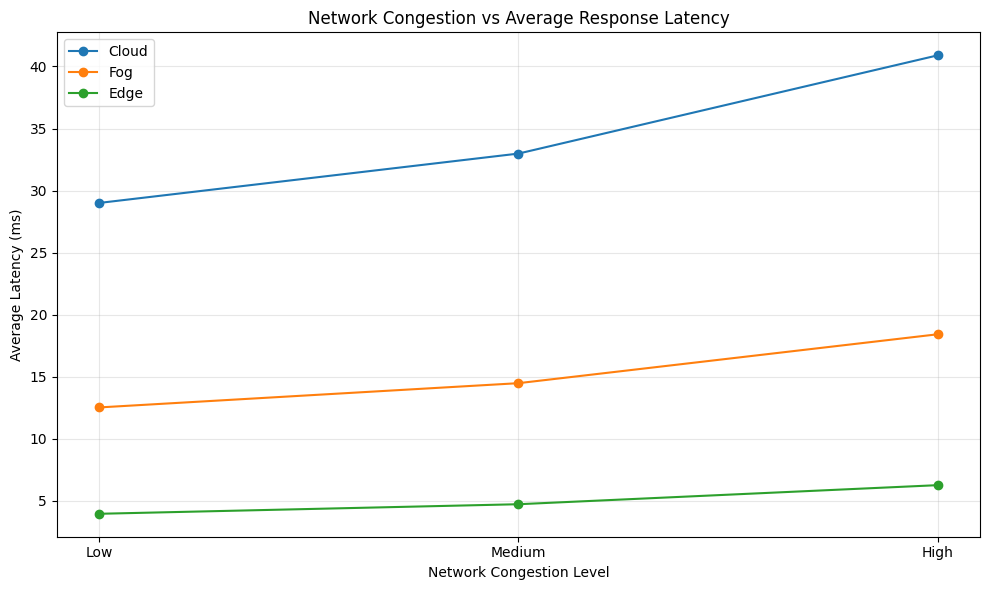

In [33]:
# ==========================================
# CONGESTION VS LATENCY
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = congestion_df[
        congestion_df["architecture"] == architecture
    ]

    plt.plot(
        data["congestion"],
        data["average_latency_ms"],
        marker="o",
        label=architecture
    )

plt.title("Network Congestion vs Average Response Latency")
plt.xlabel("Network Congestion Level")
plt.ylabel("Average Latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
# ==========================================
# EXPERIMENT 2: PROCESSING LOAD
# ==========================================

PROCESSING_LOADS = {
    "Low": 0.5,
    "Medium": 1.0,
    "High": 2.0,
    "Very High": 3.0
}

processing_results = []

for load_name, load_multiplier in PROCESSING_LOADS.items():

    for architecture_name in ARCHITECTURES:

        params = ARCHITECTURES[architecture_name]

        total_latencies = []

        for scenario_id in range(1, 1001):

            scenario = generate_scenario(scenario_id)

            # Network model
            network = NetworkModel(
                bandwidth_mbps=params["bandwidth_mbps"],
                propagation_delay_ms=params["propagation_delay_ms"],
                base_queue_delay_ms=params["base_queue_delay_ms"],
                congestion_level=params["congestion_level"]
            )

            # Higher load reduces effective processing capacity
            processing = ProcessingModel(
                processing_capacity=(
                    params["processing_capacity"]
                    / load_multiplier
                )
            )

            network_result = network.total_network_delay(
                scenario["packet_size_kb"]
            )

            processing_delay = processing.processing_delay(
                scenario["vehicle_speed_kmh"],
                scenario["obstacle_distance_m"],
                scenario["obstacle_size"]
            )

            total_latency = (
                network_result["total_network_delay_ms"]
                + processing_delay
            )

            total_latencies.append(total_latency)

        processing_results.append({
            "processing_load": load_name,
            "architecture": architecture_name,
            "average_latency_ms": np.mean(total_latencies)
        })

processing_df = pd.DataFrame(processing_results)

display(processing_df)

,processing_load,architecture,average_latency_ms
0,Low,Cloud,34.603693
1,Low,Fog,14.170477
2,Low,Edge,4.131458
3,Medium,Cloud,37.017607
4,Medium,Fog,15.278668
5,Medium,Edge,4.735670
6,High,Cloud,41.879412
7,High,Fog,17.763804
8,High,Edge,5.921319
9,Very High,Cloud,46.422648


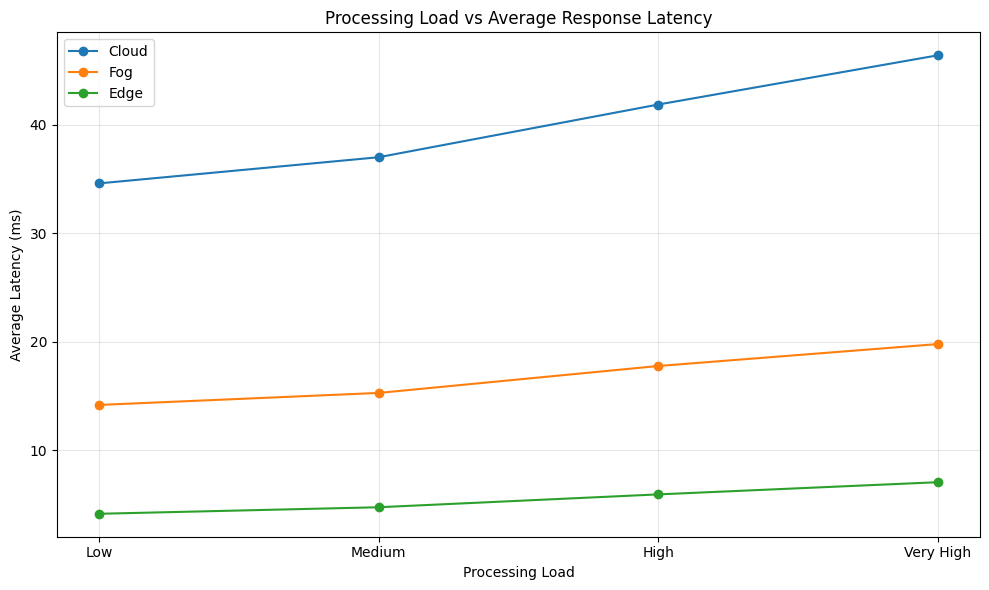

In [35]:
# ==========================================
# PROCESSING LOAD VS LATENCY
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = processing_df[
        processing_df["architecture"] == architecture
    ]

    plt.plot(
        data["processing_load"],
        data["average_latency_ms"],
        marker="o",
        label=architecture
    )

plt.title("Processing Load vs Average Response Latency")
plt.xlabel("Processing Load")
plt.ylabel("Average Latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
# ==========================================
# EXPERIMENT 3: PACKET SIZE
# ==========================================

PACKET_SIZES = [1, 2, 3, 4, 5]

bandwidth_results = []

for architecture_name in ARCHITECTURES:

    params = ARCHITECTURES[architecture_name]

    network = NetworkModel(
        bandwidth_mbps=params["bandwidth_mbps"],
        propagation_delay_ms=params["propagation_delay_ms"],
        base_queue_delay_ms=params["base_queue_delay_ms"],
        congestion_level=params["congestion_level"]
    )

    for packet_size in PACKET_SIZES:

        transmission_delay = network.transmission_delay(
            packet_size
        )

        bandwidth_results.append({
            "architecture": architecture_name,
            "packet_size_kb": packet_size,
            "transmission_delay_ms": transmission_delay
        })

packet_df = pd.DataFrame(bandwidth_results)

display(packet_df)

,architecture,packet_size_kb,transmission_delay_ms
0,Cloud,1,0.080
1,Cloud,2,0.160
2,Cloud,3,0.240
3,Cloud,4,0.320
4,Cloud,5,0.400
5,Fog,1,0.040
6,Fog,2,0.080
7,Fog,3,0.120
8,Fog,4,0.160
9,Fog,5,0.200


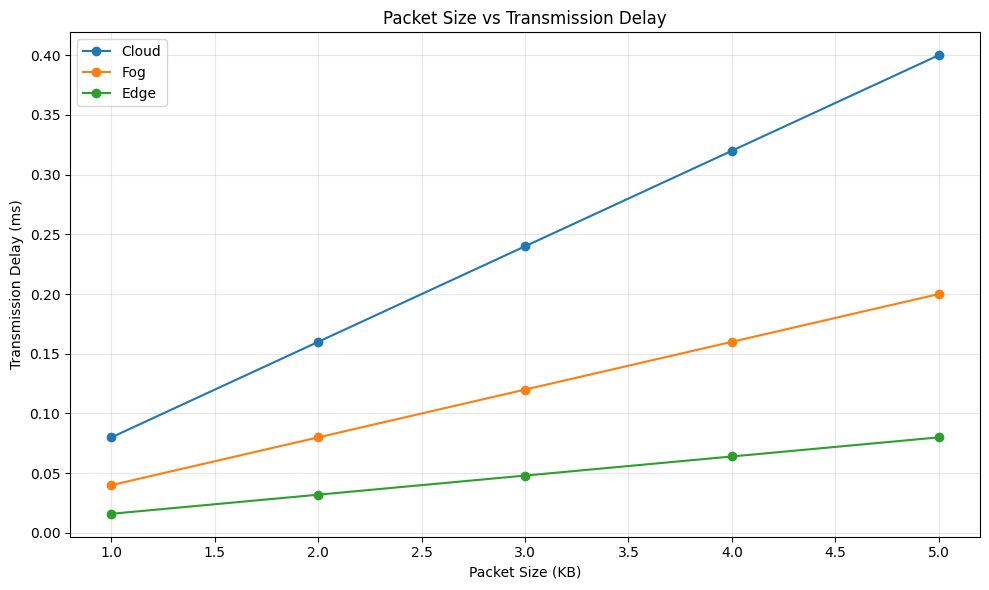

In [37]:
# ==========================================
# PACKET SIZE VS TRANSMISSION DELAY
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = packet_df[
        packet_df["architecture"] == architecture
    ]

    plt.plot(
        data["packet_size_kb"],
        data["transmission_delay_ms"],
        marker="o",
        label=architecture
    )

plt.title("Packet Size vs Transmission Delay")
plt.xlabel("Packet Size (KB)")
plt.ylabel("Transmission Delay (ms)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
# ==========================================
# EXPERIMENT 4: OBSTACLE SEVERITY ANALYSIS
# ==========================================

severity_summary = (
    results_df[
        ["scenario_id", "severity"]
    ]
    .drop_duplicates()
    ["severity"]
    .value_counts()
    .reindex(
        ["SAFE", "WARNING", "CRITICAL"],
        fill_value=0
    )
)

severity_df = pd.DataFrame({
    "severity": severity_summary.index,
    "scenario_count": severity_summary.values
})

severity_df["percentage"] = (
    severity_df["scenario_count"]
    / severity_df["scenario_count"].sum()
    * 100
).round(2)

display(severity_df)

,severity,scenario_count,percentage
0,SAFE,542,54.2
1,WARNING,357,35.7
2,CRITICAL,101,10.1


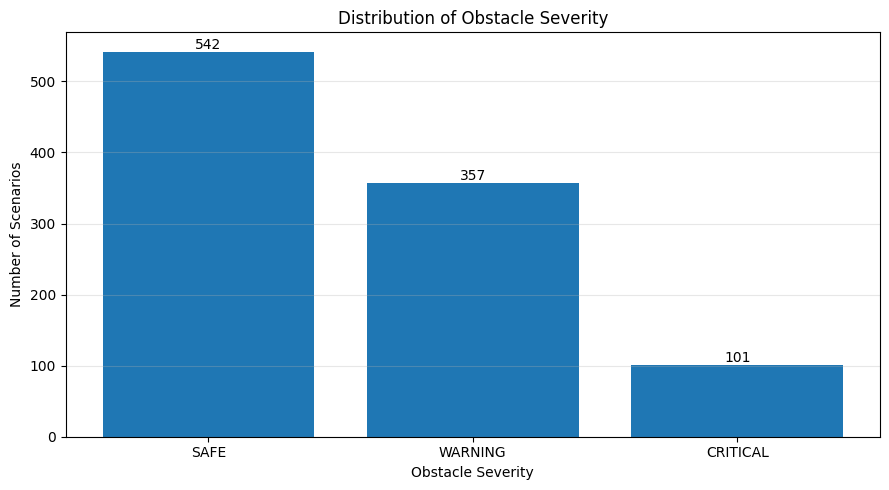

In [39]:
# ==========================================
# OBSTACLE SEVERITY DISTRIBUTION
# ==========================================

plt.figure(figsize=(9, 5))

bars = plt.bar(
    severity_df["severity"],
    severity_df["scenario_count"]
)

plt.title("Distribution of Obstacle Severity")
plt.xlabel("Obstacle Severity")
plt.ylabel("Number of Scenarios")

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    severity_df["scenario_count"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [40]:
# ==========================================
# FINAL ARCHITECTURE COMPARISON
# ==========================================

comparison_df = (
    results_df
    .groupby("architecture")
    .agg(
        scenarios=("scenario_id", "count"),
        average_latency_ms=("total_latency_ms", "mean"),
        minimum_latency_ms=("total_latency_ms", "min"),
        maximum_latency_ms=("total_latency_ms", "max"),
        network_delay_ms=("network_delay_ms", "mean"),
        processing_delay_ms=("processing_delay_ms", "mean"),
        transmission_delay_ms=("transmission_delay_ms", "mean"),
        queue_delay_ms=("queue_delay_ms", "mean"),
        propagation_delay_ms=("propagation_delay_ms", "mean")
    )
    .round(3)
)

display(comparison_df)

,scenarios,average_latency_ms,minimum_latency_ms,maximum_latency_ms,network_delay_ms,processing_delay_ms,transmission_delay_ms,queue_delay_ms,propagation_delay_ms
architecture,,,,,,,,,
Cloud,1000,36.934,31.699,45.255,32.147,4.787,0.239,11.908,20.0
Edge,1000,4.738,3.699,7.007,3.550,1.189,0.048,1.502,2.0
Fog,1000,15.298,12.971,19.664,12.919,2.379,0.120,4.799,8.0


In [41]:
# ==========================================
# LATENCY DIFFERENCE RELATIVE TO CLOUD
# ==========================================

cloud_latency = comparison_df.loc[
    "Cloud",
    "average_latency_ms"
]

comparison_df["difference_from_cloud_ms"] = (
    comparison_df["average_latency_ms"]
    - cloud_latency
).round(3)

comparison_df["percentage_difference_from_cloud"] = (
    (
        comparison_df["average_latency_ms"]
        - cloud_latency
    )
    / cloud_latency
    * 100
).round(2)

display(comparison_df)

,scenarios,average_latency_ms,minimum_latency_ms,maximum_latency_ms,network_delay_ms,processing_delay_ms,transmission_delay_ms,queue_delay_ms,propagation_delay_ms,difference_from_cloud_ms,percentage_difference_from_cloud
architecture,,,,,,,,,,,
Cloud,1000,36.934,31.699,45.255,32.147,4.787,0.239,11.908,20.0,0.000,0.00
Edge,1000,4.738,3.699,7.007,3.550,1.189,0.048,1.502,2.0,-32.196,-87.17
Fog,1000,15.298,12.971,19.664,12.919,2.379,0.120,4.799,8.0,-21.636,-58.58


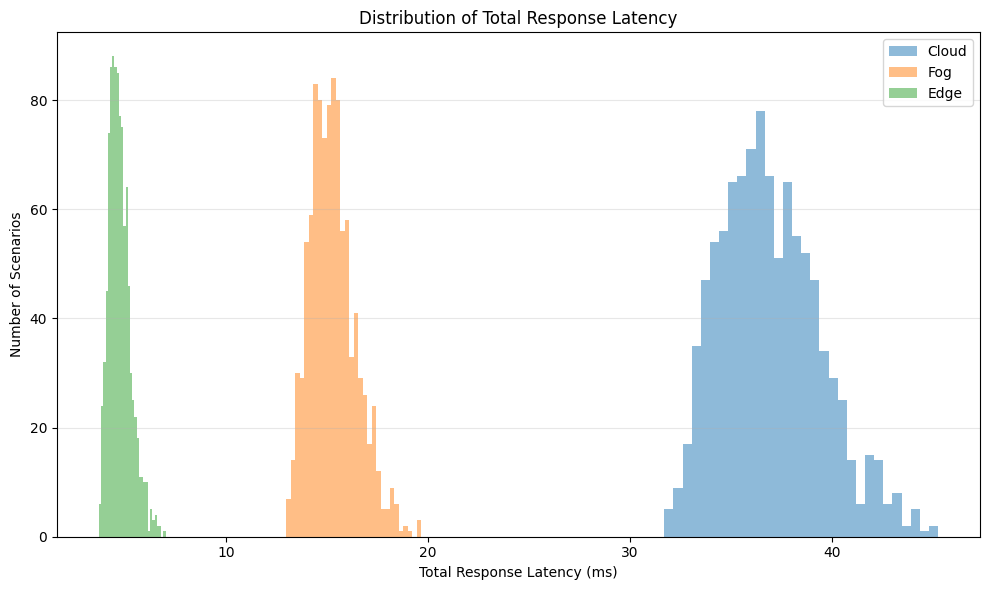

In [42]:
# ==========================================
# FINAL LATENCY DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

for architecture in ["Cloud", "Fog", "Edge"]:

    data = results_df[
        results_df["architecture"] == architecture
    ]

    plt.hist(
        data["total_latency_ms"],
        bins=30,
        alpha=0.5,
        label=architecture
    )

plt.title("Distribution of Total Response Latency")
plt.xlabel("Total Response Latency (ms)")
plt.ylabel("Number of Scenarios")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()
plt.tight_layout()
plt.show()

In [43]:
# ==========================================
# EXPORT SIMULATION RESULTS
# ==========================================

results_df.to_csv(
    "AutoEdgeSim_All_Results.csv",
    index=False
)

comparison_df.to_csv(
    "AutoEdgeSim_Architecture_Comparison.csv"
)

congestion_df.to_csv(
    "AutoEdgeSim_Congestion_Results.csv",
    index=False
)

processing_df.to_csv(
    "AutoEdgeSim_Processing_Results.csv",
    index=False
)

packet_df.to_csv(
    "AutoEdgeSim_Packet_Results.csv",
    index=False
)

severity_df.to_csv(
    "AutoEdgeSim_Severity_Results.csv",
    index=False
)

print("Export completed successfully.")
print()
print("Files created:")
print("- AutoEdgeSim_All_Results.csv")
print("- AutoEdgeSim_Architecture_Comparison.csv")
print("- AutoEdgeSim_Congestion_Results.csv")
print("- AutoEdgeSim_Processing_Results.csv")
print("- AutoEdgeSim_Packet_Results.csv")
print("- AutoEdgeSim_Severity_Results.csv")

Export completed successfully.

Files created:
- AutoEdgeSim_All_Results.csv
- AutoEdgeSim_Architecture_Comparison.csv
- AutoEdgeSim_Congestion_Results.csv
- AutoEdgeSim_Processing_Results.csv
- AutoEdgeSim_Packet_Results.csv
- AutoEdgeSim_Severity_Results.csv
